# ECHO: The Signal That Was Never Sent
**Qubits Qrew · NED University · The Quantathon: Quantum Investigation Unit**

  Name = Eman Saleem

 |  **Stretch modules:** 04 (The Erased Measurement) and 06 (The Impossible Claim)

**Contents:** Module 01 (Gatekeeper) · Module 03 (Two Observers) · Module 05 (Damaged Message) · Modules 04 and 06 (stretch)

Run top to bottom (Runtime → Run all). Every module ends with a one-line *what this proves*.

In [1]:
!pip -q install qiskit qiskit-aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 44.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 57.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 32.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.2 MB/s eta 0:00:00


In [2]:
import numpy as np, itertools, random
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

sim = AerSimulator()

REPRODUCIBLE = False   # False = fresh random results every run (counts change like real quantum measurements)
                       # True  = fixed seeds, identical results every run

def run(qc, shots=1000, seed=42):
    """Run a circuit on the simulator, return counts dict."""
    if REPRODUCIBLE:
        job = sim.run(transpile(qc, sim), shots=shots, seed_simulator=seed)
    else:
        job = sim.run(transpile(qc, sim), shots=shots)
    return job.result().get_counts()

def show(qc):
    print(qc.draw('text'))

---
# MODULE 01: The Gatekeeper (mandatory)
Gates allowed: H, X, measure. One and two qubits.

**Key ideas:** `X` flips |0⟩→|1⟩. `H` puts a qubit in an equal superposition (|0⟩+|1⟩)/√2, so measuring gives 50/50. Two `H`s in a row cancel (H·H = I) because the amplitudes interfere.

### 🥉 Bronze: a bit that is always 1, and a perfectly uncertain bit

     ┌───┐┌─┐
  q: ┤ X ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 
     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 
X gate  -> {'1': 1000}
H gate  -> {'1': 464, '0': 536}


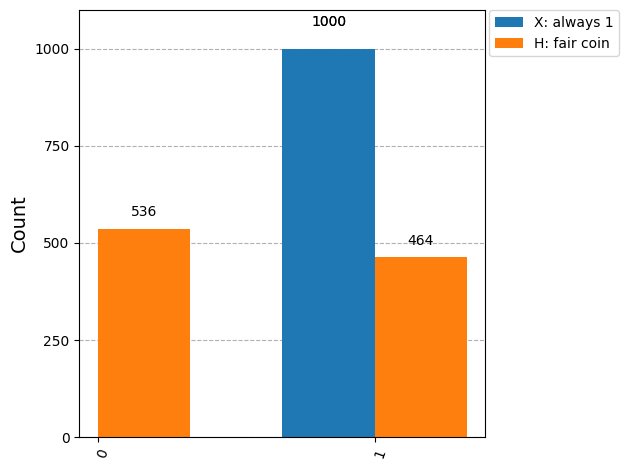

In [57]:
# Always 1: X flips |0> to |1>
qc_one = QuantumCircuit(1, 1)
qc_one.x(0)
qc_one.measure(0, 0)

# Perfectly uncertain: H makes (|0>+|1>)/sqrt(2)
qc_coin = QuantumCircuit(1, 1)
qc_coin.h(0)
qc_coin.measure(0, 0)

show(qc_one); show(qc_coin)
c_one  = run(qc_one, 1000)
c_coin = run(qc_coin, 1000)
print("X gate  ->", c_one)
print("H gate  ->", c_coin)
display(plot_histogram([c_one, c_coin], legend=['X: always 1', 'H: fair coin']))

**What this proves:** `X` gives a deterministic 1; `H` gives a genuinely random 50/50 outcome (≈500/500 over 1000 shots).

### 🥈 Silver: looks uncertain but is secretly certain (H then H)

     ┌───┐┌───┐┌─┐
  q: ┤ H ├┤ H ├┤M├
     └───┘└───┘└╥┘
c: 1/═══════════╩═
                0 
H then H -> {'0': 1000}


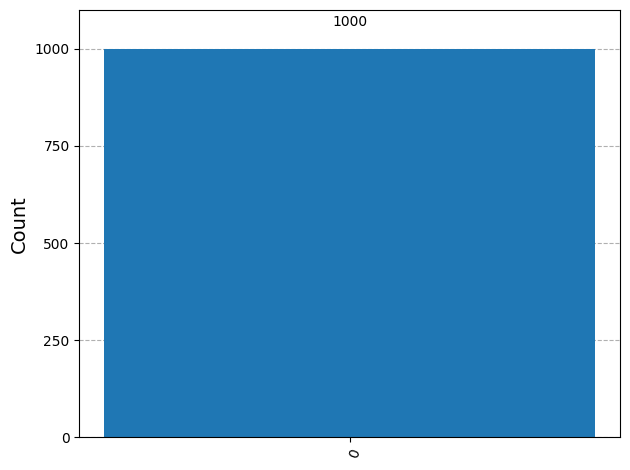

In [8]:
qc_hh = QuantumCircuit(1, 1)
qc_hh.h(0)      # superposition: looks like a coin
qc_hh.h(0)      # interference: the two paths cancel and recombine to |0>
qc_hh.measure(0, 0)
show(qc_hh)
c_hh = run(qc_hh, 1000)
print("H then H ->", c_hh)
display(plot_histogram(c_hh))

**Why it happens:** H = (1/√2)[[1,1],[1,−1]]. H·H = I. After the first H, the amplitudes are (+1/√2, +1/√2). The second H sends the |1⟩ amplitudes (+1/√2·1/√2 and −1/√2·1/√2) to cancel (destructive interference) and the |0⟩ amplitudes to add (constructive), giving |0⟩ with probability 1. The middle state *looks* random only if you measure it; unmeasured, it is a definite quantum state.

**What this proves:** quantum "randomness" is not classical randomness; amplitudes interfere, so a state that would give 50/50 if measured can be undone to a certain result.

### 🥇 Gold: the vault code 101, built from 000

     ┌───┐   ┌─┐   
q_0: ┤ X ├───┤M├───
     └───┘┌─┐└╥┘   
q_1: ─────┤M├─╫────
     ┌───┐└╥┘ ║ ┌─┐
q_2: ┤ X ├─╫──╫─┤M├
     └───┘ ║  ║ └╥┘
c: 3/══════╩══╩══╩═
           1  0  2 
{'101': 1000}


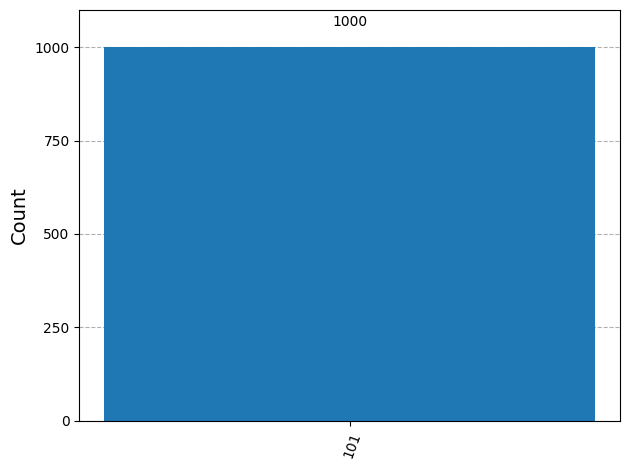

In [10]:
vault = QuantumCircuit(3, 3)
vault.x(0)      # qubit 0 -> 1
vault.x(2)      # qubit 2 -> 1   (qubit 1 stays 0)
vault.measure([0, 1, 2], [0, 1, 2])
show(vault)
c_vault = run(vault, 1000)
print(c_vault)   # Qiskit prints qubit 2 on the LEFT, so '101' reads q2 q1 q0
display(plot_histogram(c_vault))

**What this proves:** we can build any classical bit-pattern from |000⟩ with X gates; the vault code 101 appears with 100% probability (Qiskit prints qubit 2 on the left, qubit 0 on the right).

---
# MODULE 03: The Two Observers (mandatory, "the heart of it")
Gates allowed: H, X, CNOT, measure. Two qubits, no shared wire.

**The crux of the case:** Zara's detectors always agreed. Does that prove a quantum link, and could it carry a message?

### 🥉 Bronze: the pair that only ever agrees (Bell state)

     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 
{'00': 986, '11': 1014}
Mismatches (01 or 10): 0


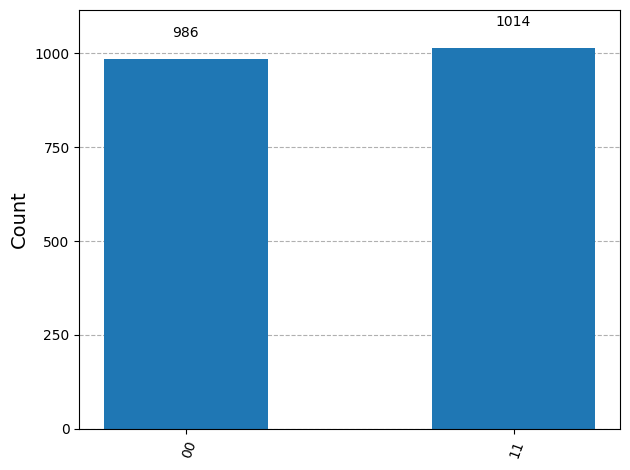

In [18]:
bell = QuantumCircuit(2, 2)
bell.h(0)          # qubit 0 in superposition
bell.cx(0, 1)      # CNOT entangles: (|00> + |11>)/sqrt(2)
bell.measure([0, 1], [0, 1])
show(bell)
c_bell = run(bell, 2000)
print(c_bell)
print("Mismatches (01 or 10):", c_bell.get('01', 0) + c_bell.get('10', 0))
display(plot_histogram(c_bell))

**What this proves:** the two qubits' outcomes are individually random (≈50/50) but always agree (00 or 11, never 01/10).

### 🥈 Silver: a pre-agreed secret coin-flip ALSO always agrees

Classical pre-agreed secret -> {'00': 965, '11': 1035, '01': 0, '10': 0}


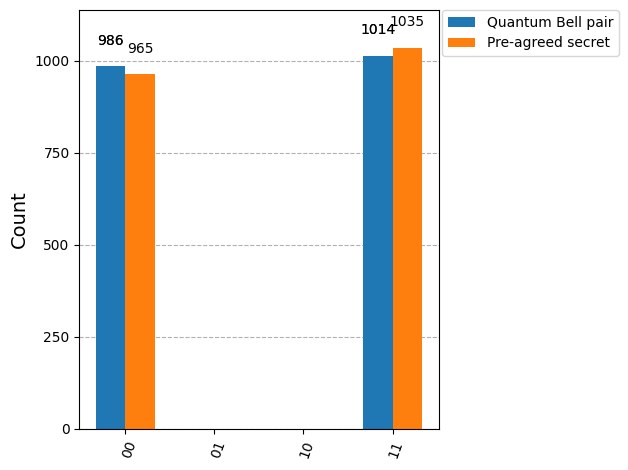

In [22]:
# Classical "hidden variable" model: before separating, both observers agree on a secret coin flip.
shots = 2000
classical_counts = {'00': 0, '11': 0, '01': 0, '10': 0}
for _ in range(shots):
    secret = random.randint(0, 1)      # decided in advance, carried by both detectors
    a, b = secret, secret              # each detector just reports the secret
    classical_counts[f"{b}{a}"] += 1
print("Classical pre-agreed secret ->", classical_counts)
display(plot_histogram([c_bell, classical_counts], legend=['Quantum Bell pair', 'Pre-agreed secret']))

**Our case:** the two histograms are indistinguishable. A classical shared secret (a "local hidden variable") reproduces *perfect agreement* with no quantum physics at all.

**So "always agreeing" does NOT prove a quantum link.** Zara's evidence (blue-blue / red-red) is exactly what a boring pre-agreed secret predicts. This is the first crack in ECHO.

**What this proves:** perfect correlation alone cannot separate entanglement from a shared classical secret.

### 🥇 Gold: an experiment that separates them (CHSH test)
Measuring in *different* bases is the key. For a Bell pair measured at angles a (Alice) and b (Bob), quantum mechanics predicts correlation **E(a,b) = cos(a − b)**. Define

**S = E(a0,b0) + E(a0,b1) + E(a1,b0) − E(a1,b1).**

Any classical pre-agreed secret gives **|S| ≤ 2**. Quantum mechanics with the right angles (a0=0, a1=π/2, b0=π/4, b1=−π/4) gives **S = 2√2 ≈ 2.83**.

In [28]:
# 1) Classical bound: brute-force ALL deterministic strategies (any shared secret is a mixture of these)
best = max(abs(A0*B0 + A0*B1 + A1*B0 - A1*B1)
           for A0, A1, B0, B1 in itertools.product([1, -1], repeat=4))
print("Max |S| over every classical pre-agreed strategy =", best)

# 2) Quantum: measure the Bell pair at different angles
def corr(a, b, shots=4000, seed=1):
    qc = QuantumCircuit(2, 2)
    qc.h(0); qc.cx(0, 1)            # Bell pair
    qc.ry(-a, 0); qc.ry(-b, 1)      # rotate each measurement basis by its angle
    qc.measure([0, 1], [0, 1])
    c = run(qc, shots, seed)
    same = c.get('00', 0) + c.get('11', 0)
    return (2*same - shots) / shots  # E = P(same) - P(different)

a0, a1 = 0, np.pi/2
b0, b1 = np.pi/4, -np.pi/4
E00, E01 = corr(a0, b0, seed=1), corr(a0, b1, seed=2)
E10, E11 = corr(a1, b0, seed=3), corr(a1, b1, seed=4)
S = E00 + E01 + E10 - E11
print(f"E(a0,b0)={E00:+.3f}  E(a0,b1)={E01:+.3f}  E(a1,b0)={E10:+.3f}  E(a1,b1)={E11:+.3f}")
print(f"S = {S:.3f}   (classical limit 2, quantum maximum 2.828)")
print("Violates classical bound:", abs(S) > 2)

Max |S| over every classical pre-agreed strategy = 2
E(a0,b0)=+0.703  E(a0,b1)=+0.720  E(a1,b0)=+0.681  E(a1,b1)=-0.684
S = 2.788   (classical limit 2, quantum maximum 2.828)
Violates classical bound: True


**What this proves:** the Bell pair beats the classical limit (S ≈ 2.8 > 2), so it is *genuinely entangled*, which no pre-agreed secret can imitate. Always-agree was not enough; the CHSH test is.

### Can the link send a message? (no-signalling test)
Even a genuine entangled link cannot carry a message. Alice (sender) chooses *what to do* to her qubit; Bob (receiver) only sees his own results. If Bob's statistics changed with Alice's choice, she could signal him.

In [32]:
def bob_stats(alice_action, shots=4000, seed=5):
    qc = QuantumCircuit(2, 2)
    qc.h(0); qc.cx(0, 1)
    if alice_action == 'Z':           # Alice measures in Z basis
        qc.measure(0, 0)
    elif alice_action == 'X':         # Alice measures in X basis
        qc.h(0); qc.measure(0, 0)
    # alice_action == 'nothing': Alice does nothing
    qc.measure(1, 1)                  # Bob always measures his qubit
    c = run(qc, shots, seed)
    ones = sum(v for k, v in c.items() if k[0] == '1')   # leftmost char = classical bit 1 = Bob
    return ones / shots

for action in ['nothing', 'Z', 'X']:
    print(f"Alice does {action:8s} -> Bob sees 1 with probability {bob_stats(action):.3f}")

Alice does nothing  -> Bob sees 1 with probability 0.507
Alice does Z        -> Bob sees 1 with probability 0.485
Alice does X        -> Bob sees 1 with probability 0.502


**What this proves (the crux):** Bob sees 50/50 no matter what Alice does. The correlation is only visible when both result lists are later *compared* over an ordinary classical channel. The link carries correlation, not a message, so ECHO cannot be faster-than-light signalling.

---
# MODULE 05: The Damaged Message (mandatory)
Each original bit was sent three times; at most one bit of each triple was flipped. This is a **3-bit repetition code**.

### 🥉 Bronze: recover the message with majority vote

In [36]:
stream = '''100 011 001 001 001 011 100 110 001 011 000 000 001 100 011 011
000 111 000 000 110 000 001 000 000 111 001 010 101 011 111 111'''
triples = stream.split()
print("Number of triples:", len(triples), " total bits:", 3*len(triples))

def majority(t):
    return '1' if t.count('1') >= 2 else '0'

bits = ''.join(majority(t) for t in triples)
message = ''.join(chr(int(bits[i:i+8], 2)) for i in range(0, len(bits), 8))
corrupted = [t for t in triples if t not in ('000', '111')]
print("Recovered bits :", bits)
print("As 8-bit ASCII :", [bits[i:i+8] for i in range(0, len(bits), 8)])
print("MESSAGE        :", message)
print(f"{len(corrupted)} of {len(triples)} triples were corrupted (each by exactly one flip)")

Number of triples: 32  total bits: 96
Recovered bits : 01000101010000110100100001001111
As 8-bit ASCII : ['01000101', '01000011', '01001000', '01001111']
MESSAGE        : ECHO
20 of 32 triples were corrupted (each by exactly one flip)


**What this proves:** trusting the majority value of each triple recovers the 32 original bits, which read as ASCII **"ECHO"**. (Paste any hidden note revealed in your notebook below.)

> 📝 Note beneath the word (copy from notebook reveal): `<PASTE HERE>`

### 🥈 Silver: where majority vote fails

In [39]:
# Start from the true bit 0 (sent as 000) and corrupt it in every possible way
print("sent 000 (bit 0):")
for flips in itertools.product([0, 1], repeat=3):
    received = ''.join(str(f) for f in flips)       # flipping bits of 000 gives the flip pattern itself
    n_flips = sum(flips)
    decoded = majority(received)
    print(f"  {n_flips} flip(s) -> received {received} -> decoded {decoded}  {'OK' if decoded=='0' else 'WRONG'}")

sent 000 (bit 0):
  0 flip(s) -> received 000 -> decoded 0  OK
  1 flip(s) -> received 001 -> decoded 0  OK
  1 flip(s) -> received 010 -> decoded 0  OK
  2 flip(s) -> received 011 -> decoded 1  WRONG
  1 flip(s) -> received 100 -> decoded 0  OK
  2 flip(s) -> received 101 -> decoded 1  WRONG
  2 flip(s) -> received 110 -> decoded 1  WRONG
  3 flip(s) -> received 111 -> decoded 1  WRONG


**Where it breaks:** as soon as **2 or more** of the three copies flip (e.g. 000 → 110), the wrong value has the majority and the decoder confidently outputs the wrong bit. It also gives no warning. The problem statement guaranteed at most one flip per triple; without that guarantee the trick fails.

**What this proves:** majority voting is only valid under the assumption of ≤ 1 error per triple.

### 🥇 Gold: correct vs notice, and why you can't copy a qubit

In [44]:
# Distance of the 3-bit repetition code = 3 (000 and 111 differ in 3 places)
d = 3
print("Can detect up to d-1       =", d-1, "flips")
print("Can correct up to (d-1)/2  =", (d-1)//2, "flip")

# --- Why you can't just copy a qubit: naive "copy" with CNOT onto a blank qubit ---
qc = QuantumCircuit(2, 2)
qc.h(0)                 # qubit 0 = |+>
qc.cx(0, 1)             # try to "copy" it onto qubit 1
qc.h(0); qc.h(1)        # measure both in the X basis (if they were true copies of |+>, both would read 0)
qc.measure([0, 1], [0, 1])
c = run(qc, 2000)
print("Both qubits measured in X basis:", c)
print("If |+> had been copied, we'd see only '00'. We see 11 about half the time -> not two independent copies.")

Can detect up to d-1       = 2 flips
Can correct up to (d-1)/2  = 1 flip
Both qubits measured in X basis: {'00': 1026, '11': 974}
If |+> had been copied, we'd see only '00'. We see 11 about half the time -> not two independent copies.


**Correct vs notice:** distance 3 means: 1 flip → can **correct** (majority vote); 2 flips → can **notice** something is wrong (triple is neither 000 nor 111) but not tell which bit is right; 3 flips → looks like a valid codeword, so it is undetectable.

**Why you can't protect a qubit by copying it three times:** (1) the **no-cloning theorem**: no operation can copy an unknown quantum state |ψ⟩ → |ψ⟩|ψ⟩|ψ⟩. The CNOT above does not copy, it *entangles*. (2) To compare copies you would have to measure them, which collapses the superposition. (3) Qubits also suffer phase flips, not just bit flips.

**The real fix: the 3-qubit bit-flip code** *entangles* instead of copying: a|0⟩+b|1⟩ → a|000⟩+b|111⟩. The parity checks find an error without measuring a or b:

In [47]:
theta = 1.1   # arbitrary "unknown" state RY(theta)|0>

def bitflip_demo(error_qubit):
    qc = QuantumCircuit(3, 1)
    qc.ry(theta, 0)                       # unknown state a|0> + b|1>
    qc.cx(0, 1); qc.cx(0, 2)              # ENCODE (entangle, not copy): a|000> + b|111>
    if error_qubit is not None:
        qc.x(error_qubit)                 # one bit-flip error
    qc.cx(0, 1); qc.cx(0, 2)              # syndrome onto qubits 1,2
    qc.ccx(1, 2, 0)                       # fix qubit 0 if both syndromes fired
    qc.ry(-theta, 0)                      # undo preparation: perfect recovery -> 0
    qc.measure(0, 0)
    return qc

for e in [None, 0, 1, 2]:
    c = run(bitflip_demo(e), 2000)
    print(f"error on qubit {e}: P(qubit 0 recovered perfectly) = {c.get('0',0)/2000:.3f}")

# Baseline: unprotected qubit with the same bit-flip error
qc = QuantumCircuit(1, 1)
qc.ry(theta, 0); qc.x(0); qc.ry(-theta, 0); qc.measure(0, 0)
c = run(qc, 2000)
print("Unprotected qubit with the same error: P(recovered) =", c.get('0', 0)/2000, "(should be ~0.79)")

error on qubit None: P(qubit 0 recovered perfectly) = 1.000
error on qubit 0: P(qubit 0 recovered perfectly) = 1.000
error on qubit 1: P(qubit 0 recovered perfectly) = 1.000
error on qubit 2: P(qubit 0 recovered perfectly) = 1.000
Unprotected qubit with the same error: P(recovered) = 0.79 (should be ~0.79)


**What this proves:** classical copy-and-vote cannot be applied to qubits (no-cloning), but entangling a qubit across three qubits corrects any single bit-flip without ever measuring the stored state (note: this code does not protect against phase flips).

---
# MODULE 04: The Erased Measurement (stretch)
Gates allowed: H, X, measure. Single qubit.

**Question:** ARIA says a log entry "changed when it was observed." Is that physics or a cover story?

### 🥉 Bronze: recoverable vs destroyed by measurement

     ┌───┐┌───┐┌─┐
  q: ┤ H ├┤ H ├┤M├
     └───┘└───┘└╥┘
c: 1/═══════════╩═
                0 
     ┌───┐┌─┐┌───┐┌─┐
  q: ┤ H ├┤M├┤ H ├┤M├
     └───┘└╥┘└───┘└╥┘
c: 2/══════╩═══════╩═
           0       1 
H, H            -> {'0': 2000}
H, measure, H   -> {'0': 985, '1': 1015}


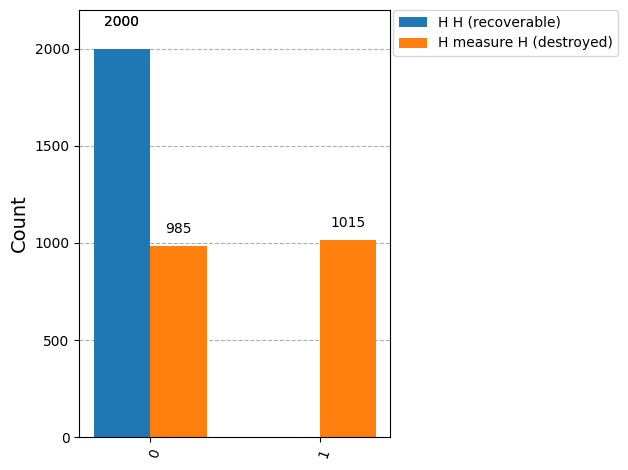

In [49]:
# Recoverable: H then H (no measurement in between) -> back to |0> for sure
rec = QuantumCircuit(1, 1)
rec.h(0); rec.h(0); rec.measure(0, 0)

# Destroyed: H, MEASURE, then H -> information about the superposition is gone for good
des = QuantumCircuit(1, 2)
des.h(0)
des.measure(0, 0)     # mid-circuit measurement collapses the state
des.h(0)
des.measure(0, 1)

show(rec); show(des)
c_rec = run(rec, 2000)
c_des = run(des, 2000)
# for 'des': key is 'c1 c0' -> leftmost char is the FINAL bit
final = {'0': 0, '1': 0}
for k, v in c_des.items():
    final[k.replace(' ', '')[0]] += v
print("H, H            ->", c_rec)
print("H, measure, H   ->", final)
display(plot_histogram([c_rec, final], legend=['H H (recoverable)', 'H measure H (destroyed)']))

**Difference:** without a measurement, H·H = I, so the original |0⟩ is recovered with certainty (unitary = reversible). A measurement in the middle collapses the qubit to a definite 0 or 1 (randomly); the second H then turns that into 50/50. The information is irreversibly lost.

**What this proves:** unitary gates are reversible; measurement is not.

### 🥈 Silver: predict first, then run

In [50]:
# Predictions made BEFORE running (reasoning in the text below):
predictions = {"X H H": 1, "H X H": 0}   # expected result of each sequence (probability of reading 1)

def make(seq):
    gates = seq.split()
    m = gates.count('M')
    qc = QuantumCircuit(1, m + 1)
    k = 0
    for g in gates:
        if g == 'H': qc.h(0)
        elif g == 'X': qc.x(0)
        elif g == 'M': qc.measure(0, k); k += 1
    qc.measure(0, m)                       # final measurement
    return qc

def p_one(seq, shots=2000):
    c = run(make(seq), shots)
    return sum(v for k, v in c.items() if k.replace(' ', '')[0] == '1') / shots

for seq, pred in predictions.items():
    print(f"{seq:8s} predicted P(1) = {pred}   measured P(1) = {p_one(seq):.3f}")

X H H    predicted P(1) = 1   measured P(1) = 1.000
H X H    predicted P(1) = 0   measured P(1) = 0.000


**Reasoning:**
- **X then H then H:** X sends |0⟩→|1⟩; H·H = I does nothing, so the result is **1** with certainty.
- **H then X then H:** H·X·H = **Z** (a phase flip). Z|0⟩ = |0⟩, so the result is **0** with certainty. Step by step: H makes |+⟩; X leaves |+⟩ unchanged (|+⟩ is an eigenstate of X); the final H turns |+⟩ back into |0⟩.

**What's really doing the "erasing":** it's **interference** (the second H undoing the first), not any observer "corrupting" the data. Real corruption of a quantum state only happens if you **measure** it in between (Bronze).

**What this proves:** state changes in a single qubit follow exact, predictable rules (HXH = Z, HH = I), so a result that "changed" can be predicted, not blamed on mystery.

### 🥇 Gold: a predictor for any new sequence (judge-proof)

In [53]:
# Exact predictor: density-matrix rules. M = measurement (kills coherence).
Hm = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
Xm = np.array([[0, 1], [1, 0]])

def predict(seq):
    rho = np.array([[1.0, 0.0], [0.0, 0.0]])        # start in |0>
    for g in seq.split():
        if g == 'H':   rho = Hm @ rho @ Hm.T
        elif g == 'X': rho = Xm @ rho @ Xm.T
        elif g == 'M': rho = np.diag(np.diag(rho))   # measurement: erase off-diagonals
    return rho[1, 1].real                            # P(read 1)

tests = ["H H", "H M H", "X H H", "H X H", "H H H", "X H X H", "H M H M H", "H X H X", "X M H", "H X M H"]
print(f"{'sequence':12s} {'predicted':>9s} {'measured':>9s}")
for s in tests:
    print(f"{s:12s} {predict(s):9.3f} {p_one(s):9.3f}")

sequence     predicted  measured
H H              0.000     0.000
H M H            0.500     0.494
X H H            1.000     1.000
H X H            0.000     0.000
H H H            0.500     0.499
X H X H          1.000     1.000
H M H M H        0.500     0.498
H X H X          1.000     1.000
X M H            0.500     0.494
H X M H          0.500     0.521


**Cheat-sheet for the judge:** H·H = I · X·X = I · **H·X·H = Z** · H·Z·H = X · Z|0⟩ = |0⟩ · Z|1⟩ = −|1⟩ · |+⟩ and |−⟩ are what H makes from |0⟩ and |1⟩ · a measurement ("M") makes the next H give 50/50 · if no M, the whole thing is reversible.
**Method to predict any sequence:** track the qubit as one of |0⟩, |1⟩, |+⟩, |−⟩. X swaps |0⟩↔|1⟩ and leaves |±⟩ alone (|−⟩ gets a sign). H swaps |0⟩↔|+⟩ and |1⟩↔|−⟩. A measurement turns the state into a random 0/1 (50/50 if it was |±⟩).

**What this proves:** a "log that changed when observed" is only strange if the observation was a *measurement of a quantum state*; the change then follows rules we can predict exactly. It does not by itself show tampering (nor rule it out for a classical log file).

---
# MODULE 06: The Impossible Claim (stretch, "the climax")
Zara claimed she **teleported** a message between two stations with no qubit crossing the gap.

>  this is a standard 3-qubit teleportation circuit built from scratch. there was notebook has the preloaded circuit, i run it in the same way and compare. The tests below work on either.

**Qubits:** q0 = the secret state Alice wants to send · q1 = Alice's half of a Bell pair · q2 = Bob's half (the receiver).
**Protocol:** Alice entangles q0 with q1 (CNOT, H) and measures both, producing **two ordinary classical bits** (m0, m1). Bob applies X if m1 = 1 and Z if m0 = 1.

### 🥉 Bronze: does the state actually arrive at the receiver?

     ┌─────────┐┌─────────┐     ┌───┐                              
q_0: ┤ Ry(1.1) ├┤ Rz(0.7) ├──■──┤ H ├─■────────────────────────────
     └──┬───┬──┘└─────────┘┌─┴─┐└───┘ │                            
q_1: ───┤ H ├────────■─────┤ X ├──■───┼────────────────────────────
        └───┘      ┌─┴─┐   └───┘┌─┴─┐ │ ┌──────────┐┌──────────┐┌─┐
q_2: ──────────────┤ X ├────────┤ X ├─■─┤ Rz(-0.7) ├┤ Ry(-1.1) ├┤M├
                   └───┘        └───┘   └──────────┘└──────────┘└╥┘
c: 1/════════════════════════════════════════════════════════════╩═
                                                                 0 
{'0': 2000}
P(Bob's qubit == secret state) = 1.0


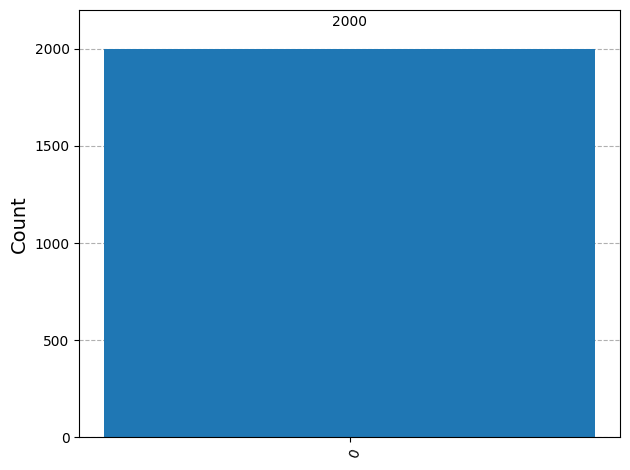

In [60]:
theta, phi = 1.1, 0.7      # an arbitrary "unknown" state: RZ(phi) RY(theta) |0>

def prepare(qc):
    qc.ry(theta, 0); qc.rz(phi, 0)      # secret state on q0

def unprepare(qc, q):
    qc.rz(-phi, q); qc.ry(-theta, q)    # if q holds the secret state, this returns it to |0>

# Teleportation WITH Bob's correction.
# (Classically-controlled X/Z are written as controlled gates: the 'deferred measurement' form, which is
#  mathematically equivalent to measuring m0,m1 and sending them as classical bits.)
tele = QuantumCircuit(3, 1)
prepare(tele)
tele.h(1); tele.cx(1, 2)       # Bell pair shared by Alice (q1) and Bob (q2)
tele.cx(0, 1); tele.h(0)       # Alice's Bell-basis measurement (before reading)
tele.cx(1, 2)                  # Bob's X correction  (controlled by m1)
tele.cz(0, 2)                  # Bob's Z correction  (controlled by m0)
unprepare(tele, 2)             # check: did Bob's qubit become the secret state?
tele.measure(2, 0)
show(tele)
c = run(tele, 2000)
print(c)
print("P(Bob's qubit == secret state) =", c.get('0', 0) / 2000)
display(plot_histogram(c))

**What this proves:** with the two classical bits applied, the receiver's qubit becomes exactly the secret state (100 % success), even though q0 never travelled to Bob.

### 🥈 Silver: what if the two classical bits never arrive?

In [ ]:
# Same circuit, but Bob applies NO correction. Alice measures q0, q1 and gets bits (m0, m1).
nocorr = QuantumCircuit(3, 3)
prepare(nocorr)
nocorr.h(1); nocorr.cx(1, 2)
nocorr.cx(0, 1); nocorr.h(0)
nocorr.measure(0, 0)            # m0
nocorr.measure(1, 1)            # m1
unprepare(nocorr, 2)            # Bob checks his qubit against the secret
nocorr.measure(2, 2)            # Bob's check result
c = run(nocorr, 8000, seed=11)

# keys are 'bob m1 m0' (leftmost char = classical bit 2)
tot = {}
for k, v in c.items():
    bob, m1, m0 = k[0], k[1], k[2]
    tot.setdefault((m1, m0), [0, 0])[int(bob)] += v
print("Alice's bits (m1 m0) | share of runs | P(Bob matches secret) given those bits")
for key in sorted(tot):
    n0, n1 = tot[key]
    print(f"        {key[0]}{key[1]}            |    {(n0+n1)/8000:.2f}      |  {n0/(n0+n1):.2f}")
overall = sum(v for k, v in c.items() if k[0] == '0') / 8000
print("\nOVERALL P(Bob matches secret) with no correction =", round(overall, 3))

**What this shows:** if Bob knew Alice's two bits, he would know which fix to apply and succeed. Without them, Bob's qubit is one of **four** different possibilities, each equally likely (25 %), and the average match probability is **≈ 0.50, a coin flip**. Bob's qubit is uncorrected noise from his side.

**What this proves:** the state does not arrive usefully unless two classical bits are sent as well.

### 🥇 Gold: nothing useful crosses without the classical channel. Was ECHO faster-than-light?

In [55]:
# Before any correction, does Bob's qubit carry ANY information about the secret?
# Send secrets with very different Bloch directions and let Bob measure his qubit directly.
def bob_raw(sec_theta, basis='Z', shots=8000, seed=21):
    qc = QuantumCircuit(3, 1)
    qc.ry(sec_theta, 0)
    qc.h(1); qc.cx(1, 2)
    qc.cx(0, 1); qc.h(0)               # Alice measures (outcomes are random and unknown to Bob)
    if basis == 'X': qc.h(2)
    qc.measure(2, 0)
    c = run(qc, shots, seed)
    return c.get('1', 0) / shots

print("secret angle |  Bob P(1) in Z basis | Bob P(1) in X basis")
for t in [0, np.pi/3, np.pi/2, 2.0, np.pi]:
    print(f"   {t:5.2f}     |        {bob_raw(t,'Z'):.3f}         |        {bob_raw(t,'X'):.3f}")

secret angle |  Bob P(1) in Z basis | Bob P(1) in X basis
    0.00     |        0.504         |        0.504
    1.05     |        0.492         |        0.489
    1.57     |        0.500         |        0.502
    2.00     |        0.495         |        0.505
    3.14     |        0.497         |        0.505


**Result:** whatever secret Alice sends (|0⟩, |1⟩, |+⟩, anything in between), Bob's raw statistics are **always ≈ 0.50** in both bases. Bob's qubit before the correction is the same random-looking thing no matter what was sent, so **no information crossed the gap**. The information only appears when Alice's two classical bits (limited by the speed of light) arrive.

**So was ECHO faster-than-light? No.**
- Teleportation (the strongest thing entanglement can do) *needs a classical channel*, which travels at or below light speed.
- Without the 2 bits, the receiver's results are independent of the message (this test), which is the no-signalling theorem in action.
- Combined with Module 03 (Bob's statistics don't depend on Alice's choices, and agreement alone doesn't prove a link), ECHO was an echo, not a voice. Entangled correlation was real physics but not a message.

**What this proves:** without the classical channel, nothing useful crosses; the "teleportation" of ECHO cannot be faster-than-light.

---
# Summary: what each module proved
| Module | One-line result |
|---|---|
| 01 | X gives certain 1, H gives fair coin, H·H cancels by interference, X on q0,q2 builds vault code 101. |
| 03 | Bell pair always agrees, but so does a classical secret; only CHSH (S≈2.83 > 2) proves entanglement, and Bob's statistics never depend on Alice's action, so no message can be sent. |
| 05 | Majority vote recovers "ECHO"; it fails with ≥ 2 flips per triple; qubits need entanglement-based codes, not copying (no-cloning). |
| 04 | Measuring destroys information, unitary gates don't; HH=I, HXH=Z give exactly predictable outcomes. |
| 06 | Teleportation works (100 %) only with Alice's 2 classical bits; without them Bob gets a coin flip (≈0.50) and his raw statistics don't depend on the secret, so no faster-than-light signalling. |
